# Inference for a 2D Gaussian mean vector (known $\Sigma$)

Special case of the linear Gaussian system $y_i = W z + b + \varepsilon_i$, with
$$z=\mu,\qquad W=I_2,\qquad b=0,\qquad \Sigma_y=\Sigma,\qquad \mu_z=\mu_0,\qquad \Sigma_z=\Lambda_0 .$$

**Model**
$$y_i\mid\mu\sim\mathcal N(\mu,\Sigma),\quad i=1,\dots,n,\qquad \mu\sim\mathcal N(\mu_0,\Lambda_0)$$

**Posterior** $\;p(\mu\mid y_{1:n})=\mathcal N(\mu_n,\Lambda_n)$
$$\Lambda_n^{-1}=\Lambda_0^{-1}+n\,\Sigma^{-1},\qquad \mu_n=\Lambda_n\big(\Lambda_0^{-1}\mu_0+n\,\Sigma^{-1}\bar y\big)$$

## Data

Fisher's iris data, *Iris setosa* only ($n=50$): $y_i=(\text{sepal length},\ \text{sepal width})^T$ in cm.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.datasets import load_iris

X, lab = load_iris(return_X_y=True)
Y = X[lab == 0][:, :2]          # 50 x 2
n_all = len(Y)
Y[:3], Y.shape

(array([[5.1, 3.5],
        [4.9, 3. ],
        [4.7, 3.2]]),
 (50, 2))

## Inputs

$\Sigma$ is treated as **known** (here: plugged in from the sample covariance). The prior is our choice.

$$
\Sigma=\begin{pmatrix}0.124 & 0.099\\ 0.099 & 0.144\end{pmatrix},\qquad
\mu_0=\begin{pmatrix}5.5\\ 3.0\end{pmatrix},\qquad
\Lambda_0=\begin{pmatrix}0.25 & 0\\ 0 & 0.25\end{pmatrix}
$$

In [3]:
Sigma = np.cov(Y.T)                 # plug-in, treated as known
mu0   = np.array([5.5, 3.0])
Lam0  = 0.25 * np.eye(2)
Sinv, L0inv = np.linalg.inv(Sigma), np.linalg.inv(Lam0)
print(np.round(Sigma, 3))

[[0.124 0.099]
 [0.099 0.144]]


## Posterior

In [4]:
def posterior(n):
    if n == 0:
        return mu0, Lam0
    ybar = Y[:n].mean(axis=0)
    Lam_n = np.linalg.inv(L0inv + n * Sinv)
    mu_n = Lam_n @ (L0inv @ mu0 + n * Sinv @ ybar)
    return mu_n, Lam_n

for n in (0, 1, 3, 50):
    m, L = posterior(n)
    sd = np.sqrt(np.diag(L))
    print(f"n={n:2d}  mean={np.round(m,3)}  sd={np.round(sd,3)}  corr={L[0,1]/sd.prod():.2f}")

n= 0  mean=[5.5 3. ]  sd=[0.5 0.5]  corr=0.00
n= 1  mean=[5.123 3.412]  sd=[0.267 0.283]  corr=0.60
n= 3  mean=[4.956 3.256]  sd=[0.181 0.194]  corr=0.69
n=50  mean=[5.008 3.427]  sd=[0.049 0.053]  corr=0.74


## Result at $n=50$

$$
\bar y=\begin{pmatrix}5.006\\ 3.428\end{pmatrix},\qquad
\mu_{50}=\begin{pmatrix}5.008\\ 3.427\end{pmatrix},\qquad
\Lambda_{50}=\begin{pmatrix}0.00245 & 0.00194\\ 0.00194 & 0.00283\end{pmatrix}
$$

Posterior precision $\Lambda_{50}^{-1}=\Lambda_0^{-1}+50\,\Sigma^{-1}=\begin{pmatrix}901.0 & -619.4\\ -619.4 & 779.6\end{pmatrix}$.

In [5]:
m50, L50 = posterior(50)
print(np.round(m50, 4)); print(np.round(L50, 5)); print(np.round(np.linalg.inv(L50), 1))

[5.0075 3.427 ]
[[0.00245 0.00194]
 [0.00194 0.00283]]
[[ 901.  -619.4]
 [-619.4  779.6]]


## Plot: posterior shrinks toward $\bar y$ and acquires the correlation of $\Sigma$

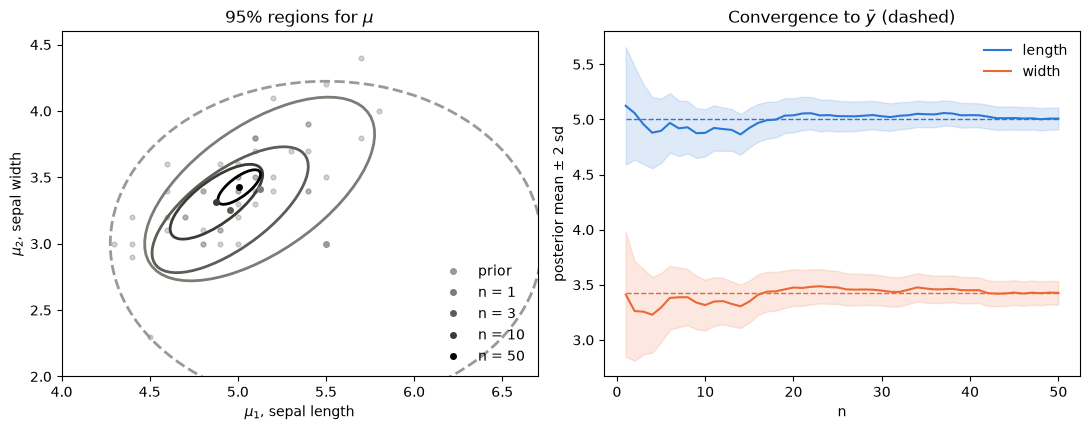

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))

# (a) 95% regions for mu
ax = axs[0]
ax.scatter(Y[:, 0], Y[:, 1], s=12, color="gray", alpha=0.35)
k = np.sqrt(5.991)                       # 95% for 2D Gaussian
for n, c in {0: "#9a9993", 1: "#7c7b75", 3: "#5d5c57", 10: "#3b3a37", 50: "k"}.items():
    m, L = posterior(n)
    w, v = np.linalg.eigh(L)
    ang = np.degrees(np.arctan2(v[1, 1], v[0, 1]))
    ax.add_patch(Ellipse(m, 2*k*np.sqrt(w[1]), 2*k*np.sqrt(w[0]), angle=ang, fill=False,
                         ec=c, lw=2, ls="--" if n == 0 else "-"))
    ax.plot(*m, "o", color=c, ms=4, label="prior" if n == 0 else f"n = {n}")
ax.set_xlim(4.0, 6.7); ax.set_ylim(2.0, 4.6)
ax.set_xlabel(r"$\mu_1$, sepal length"); ax.set_ylabel(r"$\mu_2$, sepal width")
ax.set_title("95% regions for $\\mu$"); ax.legend(frameon=False, loc="lower right")

# (b) posterior mean and sd versus n
ax = axs[1]
ns = np.arange(1, n_all + 1)
M = np.array([posterior(n)[0] for n in ns])
S = np.array([np.sqrt(np.diag(posterior(n)[1])) for n in ns])
for j, (c, nm) in enumerate([("#2a78d6", "length"), ("#eb6834", "width")]):
    ax.plot(ns, M[:, j], color=c, label=nm)
    ax.fill_between(ns, M[:, j] - 2*S[:, j], M[:, j] + 2*S[:, j], color=c, alpha=0.15)
    ax.hlines(Y[:, j].mean(), 1, n_all, color=c, ls="--", lw=1)
ax.set_xlabel("n"); ax.set_ylabel(r"posterior mean $\pm$ 2 sd"); ax.set_title("Convergence to $\\bar y$ (dashed)")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()